# 03 — Entraînement et évaluation des modèles (emails) — v2

**Pourquoi refaire ce notebook.** La v1 avait trois faiblesses qu'un jury relèverait :
1. le modèle final était choisi **sur le jeu de test** (meilleur recall à seuil 0,5) : le test n'était plus indépendant ;
2. le choix reposait sur **un seul split** et sur **une seule métrique** (le recall à 0,5, qu'on améliore trivialement en baissant le seuil) ;
3. la régression logistique **ne convergeait pas** (features numériques non normalisées, `body_length` jusqu'à 4 millions), donc la « comparaison » LR vs XGBoost n'était pas équitable.

**Protocole de cette version**
- Toutes les décisions (features, famille de modèle, hyperparamètres, blend, seuil) se prennent par **validation croisée groupée à 5 plis sur le train uniquement** : les plis sont fixés une fois et réutilisés pour tous les modèles, ce qui permet des **comparaisons appariées** (même plis, mêmes emails).
- Le **test n'est touché qu'une seule fois**, à la fin, pour le modèle déjà choisi et son seuil déjà fixé.
- Métrique principale de sélection : **average precision** (aire sous la courbe précision-rappel de la classe phishing) — indépendante du seuil et centrée sur la classe qui compte. Le recall n'est regardé qu'**à seuil choisi**, parce qu'un faux négatif (phishing classé sûr) coûte plus cher qu'un faux positif.
- **Règle de décision** : on part du modèle le plus simple et on ne passe à plus complexe que si le gain est à la fois supérieur à `MIN_GAIN` et à 2 erreurs-types des différences par pli. À performance équivalente, le simple gagne (plus rapide, interprétable, probabilités mieux calibrées pour la cascade ML → LLM).

Étapes :
1. Charger les données et fixer les plis de validation croisée
2. Choisir le jeu de features (numériques ? marqueurs de source ?)
3. Comparer plusieurs familles de modèles
4. Régler les hyperparamètres des meilleures familles
5. Tester un blend (LR + XGBoost) sur des prédictions out-of-fold
6. Calibration, seuil de décision et zone d'incertitude pour la cascade
7. Évaluation finale sur le test (une seule fois) + intervalles de confiance
8. Ce que le modèle regarde, sauvegarde et rechargement

In [1]:
import json
import time
import warnings
from datetime import date
from functools import partial
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import seaborn as sns
import sklearn
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, classification_report,
                             confusion_matrix, f1_score, make_scorer, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from xgboost import XGBClassifier

sns.set_style("whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
N_SPLITS = 5
QUICK = False   # True = sous-échantillon de 15 000 emails, pour un essai rapide du notebook
MIN_GAIN = 0.001   # gain minimal d'average precision (0,1 point) pour justifier plus de complexité

DATA = Path("../data/processed")
MODELS = Path("../models")
FIGS = Path("../notebooks")
MODELS.mkdir(exist_ok=True)

## 1. Charger les données et fixer les plis de validation croisée

On charge le train (TF-IDF + 3 features numériques en `log1p`), les labels, les **groupes de quasi-doublons** et les noms de colonnes. Le test est chargé plus tard, à la section 7.

Les plis sont calculés **une seule fois** (`splits`) et réutilisés partout : tous les modèles sont jugés sur les mêmes emails, ce qui rend les différences par pli comparables (comparaison appariée).

In [2]:
X_all = sp.load_npz(DATA / "emails_X_train.npz").tocsr()
y = np.load(DATA / "emails_y_train.npy")
names = np.array(json.load(open(DATA / "emails_feature_names.json", encoding="utf-8")))
groups_path = DATA / "emails_groups_train.npy"
groups = np.load(groups_path) if groups_path.exists() else None

NUM_NAMES = ["body_length", "num_words", "num_urgent_words"]
N_NUM = len(NUM_NAMES)
assert X_all.shape[1] == len(names) and list(names[-N_NUM:]) == NUM_NAMES, "Relancer le notebook 02 (v3)."

if QUICK:
    rng = np.random.RandomState(RANDOM_STATE)
    idx = np.sort(rng.choice(len(y), size=min(15000, len(y)), replace=False))
    X_all, y = X_all[idx], y[idx]
    groups = groups[idx] if groups is not None else None

print("X_train:", X_all.shape, "| phishing :", round(y.mean(), 3), "| groupes :", None if groups is None else len(np.unique(groups)))

X_train: (62040, 5003) | phishing : 0.495 | groupes : 59831


In [3]:
if groups is not None:
    splitter = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
    splits = list(splitter.split(X_all, y, groups))
else:
    print("ATTENTION : pas de groupes -> validation croisée non groupée (risque de fuite par quasi-doublons).")
    splits = list(StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE).split(X_all, y))

for k, (tr, va) in enumerate(splits):
    overlap = len(set(groups[tr]) & set(groups[va])) if groups is not None else "n/a"
    print(f"pli {k}: train={len(tr):>6} val={len(va):>6} | phishing val={y[va].mean():.3f} | groupes communs={overlap}")

pli 0: train= 49632 val= 12408 | phishing val=0.495 | groupes communs=0
pli 1: train= 49632 val= 12408 | phishing val=0.495 | groupes communs=0
pli 2: train= 49632 val= 12408 | phishing val=0.495 | groupes communs=0
pli 3: train= 49632 val= 12408 | phishing val=0.495 | groupes communs=0
pli 4: train= 49632 val= 12408 | phishing val=0.495 | groupes communs=0


### Fonctions utilitaires

- `run_cv` évalue une configuration sur les plis fixés et garde les scores **par pli** (indispensable pour la comparaison appariée).
- `is_better` applique la règle de décision : gain moyen d'average precision > `MIN_GAIN` **et** > 2 erreurs-types des différences par pli. Les plis ne sont pas indépendants (leurs données d'entraînement se recouvrent), donc l'erreur-type est un peu optimiste : c'est pourquoi on exige aussi `MIN_GAIN`.

In [4]:
SCORING = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "f1": "f1",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": "recall",
}


def run_cv(name, estimator, X, store):
    """Validation croisée sur les plis fixés ; scores par pli rangés dans store[name]."""
    t0 = time.time()
    res = cross_validate(estimator, X, y, cv=splits, scoring=SCORING, n_jobs=1, error_score="raise")
    store[name] = {k: np.asarray(res[f"test_{k}"]) for k in SCORING}
    store[name]["fit_time"] = float(np.mean(res["fit_time"]))
    ap = store[name]["average_precision"]
    print(f"{name:<45} AP={ap.mean():.4f} ± {ap.std(ddof=1):.4f} | {time.time() - t0:5.0f}s")
    return store[name]


def summary_table(store):
    rows = []
    for name, sc in store.items():
        row = {"modèle": name}
        for m in ["average_precision", "roc_auc", "recall", "precision", "f1"]:
            row[m] = f"{sc[m].mean():.4f} ± {sc[m].std(ddof=1):.4f}"
        row["fit (s/pli)"] = round(sc["fit_time"], 1)
        rows.append(row)
    return pd.DataFrame(rows).set_index("modèle")


def paired_gain(candidate, reference):
    """Gain moyen et erreur-type des différences par pli (candidate - reference)."""
    d = np.asarray(candidate) - np.asarray(reference)
    return d.mean(), d.std(ddof=1) / np.sqrt(len(d))


def is_better(candidate, reference, min_gain=MIN_GAIN):
    gain, se = paired_gain(candidate, reference)
    return bool(gain > min_gain and gain > 2 * se), gain, se

## 2. Choisir le jeu de features

Trois questions, tranchées par validation croisée avec une **régression logistique** (rapide, donc idéale pour comparer des jeux de features) :

1. Les 3 features numériques apportent-elles quelque chose au-delà du TF-IDF ? Elles décrivent surtout la **longueur** des emails, un trait qui peut refléter la façon dont les corpus d'origine ont été collectés plutôt que le phishing.
2. Que valent-elles seules ? (un score élevé avec 3 colonnes signalerait un biais de corpus)
3. Que coûte le retrait des **marqueurs de source** (`enron`, `ect`, `cnn`…) identifiés au notebook 02 ? Un marqueur de source ne se généralise pas à de vrais emails d'aujourd'hui : si le coût est faible, on les retire par construction.

Côté mise en forme : le TF-IDF est déjà à l'échelle (lignes normalisées), mais les features numériques (même en `log1p`) ont une autre échelle. Pour les modèles linéaires, elles passent donc par un `StandardScaler` **dans le pipeline** (ajusté uniquement sur le train de chaque pli). Les arbres n'en ont pas besoin.

In [5]:
def linear_pipeline(clf, n_cols, n_num):
    """Modèle linéaire ; si des colonnes numériques sont présentes (en dernier), elles sont standardisées.
    L'ordre des colonnes est conservé (TF-IDF d'abord, numériques ensuite)."""
    if n_num == 0:
        return clf
    pre = ColumnTransformer(
        [("tfidf", "passthrough", np.arange(n_cols - n_num)),
         ("num", StandardScaler(with_mean=False), np.arange(n_cols - n_num, n_cols))],
        sparse_threshold=1.0,
    )
    return Pipeline([("pre", pre), ("clf", clf)])


def make_logreg(n_cols, n_num, C=1.0):
    return linear_pipeline(LogisticRegression(C=C, max_iter=2000, random_state=RANDOM_STATE), n_cols, n_num)


n_tfidf = X_all.shape[1] - N_NUM
X_tfidf_only = X_all[:, :n_tfidf]
X_num_only = X_all[:, n_tfidf:]

feature_runs = {}
run_cv("TF-IDF seul", make_logreg(n_tfidf, 0), X_tfidf_only, feature_runs)
run_cv("TF-IDF + numériques", make_logreg(X_all.shape[1], N_NUM), X_all, feature_runs)
run_cv("Numériques seuls (3 colonnes)", make_logreg(N_NUM, N_NUM), X_num_only, feature_runs)

TF-IDF seul                                   AP=0.9957 ± 0.0034 |     2s
TF-IDF + numériques                           AP=0.9955 ± 0.0034 |    13s
Numériques seuls (3 colonnes)                 AP=0.6641 ± 0.0063 |     1s


{'roc_auc': array([0.71285103, 0.70855263, 0.70440268, 0.70265002, 0.70852205]),
 'average_precision': array([0.67386554, 0.66226295, 0.6567243 , 0.6622828 , 0.66541765]),
 'f1': array([0.68010882, 0.6764565 , 0.68068499, 0.67537882, 0.66726065]),
 'precision': array([0.66834408, 0.66312001, 0.66609509, 0.66508764, 0.66360561]),
 'recall': array([0.69229516, 0.69034045, 0.69592834, 0.68599349, 0.67095618]),
 'fit_time': 0.07265939712524414}

In [6]:
keep_num, gain_num, se_num = is_better(feature_runs["TF-IDF + numériques"]["average_precision"],
                                       feature_runs["TF-IDF seul"]["average_precision"])
USE_NUMERIC = keep_num
print(f"Gain d'AP apporté par les numériques : {gain_num:+.4f} (erreur-type {se_num:.4f})")
print("DÉCISION :", "on garde les features numériques" if USE_NUMERIC
      else "on les retire : gain non démontré, et risque de biais de longueur propre au corpus")

Gain d'AP apporté par les numériques : -0.0002 (erreur-type 0.0000)
DÉCISION : on les retire : gain non démontré, et risque de biais de longueur propre au corpus


### Marqueurs de source

La liste ci-dessous vient de l'inspection du notebook 02 (tokens qui désignent une source : entreprise, personnes, listes de diffusion, médias). Elle est volontairement courte et explicite, pour rester défendable : on n'enlève pas « tout ce qui score fort », seulement ce qui n'a aucun sens hors du corpus.

On compare : TF-IDF complet vs TF-IDF sans ces colonnes.

In [7]:
SOURCE_MARKERS = [
    # Corpus Enron (légitime à 100 %) : entreprise, personnes, jargon interne
    "enron", "enron com", "enron corp", "enron enron", "enron enronxgate", "enron north", "enron subject",
    "enronxgate", "corp enron", "ect enron", "ect", "ect ect", "ect subject", "hou", "hou ect",
    "vince", "kaminski", "kaminski enron", "kaminski hou", "vince kaminski", "vince weiguang", "weiguang",
    "say vince", "america corp", "louise", "kitchen louise", "hpl", "ena", "scheduling", "scheduling iso",
    "california scheduling", "westdesk", "portland westdesk", "westdesk california", "hourahead",
    "hourahead hour", "date hourahead", "hour start", "hour ancillary", "ancillary schedules",
    "schedules awarded", "awarded variances", "variances detected", "variances", "detected log",
    "final schedules", "schedules txt", "iso final", "file portland", "mmbtu", "start date",
    # Listes de diffusion techniques (python-dev, opensuse, perl, linguistique) : légitimes à ~100 %
    "python", "pythondev", "pythondev mailing", "unsubscribe pythondev", "guido", "guido van", "rossum",
    "van rossum", "opensuse", "suse", "perl", "uai", "linguistics", "linguistic", "computational",
    "theoretical", "semantics", "parsing", "parsing file", "syntax", "gnupg", "gnulinux", "version gnupg",
    "pgp signed", "signed message", "message hash", "log messages", "messages parsing", "list unsubscribe",
    "httpmailpythonorgmailmanlistinfopythondev", "httpmailpythonorgmailmanlistinfopythondev unsubscribe",
    "zvlllneumpythonorg", "list zvlllneumpythonorg",
    "zvlllneumpythonorg httpmailpythonorgmailmanlistinfopythondev",
    # Corpus SpamAssassin / flux RSS
    "rssfeedsspamassassintaintorg", "rssfeedsspamassassintaintorg url", "url date",
    # Source phishing identifiable (adresse d'un collecteur de spam)
    "josemonkeyorg",
    # Gabarit CNN : normalement déjà retiré au notebook 01 ; ignoré s'il est absent du vocabulaire
    "cnn", "cnncom",
]

vocab_index = {w: i for i, w in enumerate(names[:n_tfidf])}
found = [w for w in SOURCE_MARKERS if w in vocab_index]
print("Marqueurs trouvés dans le vocabulaire :", found)
print("Absents (ignorés)                    :", [w for w in SOURCE_MARKERS if w not in vocab_index])
marker_cols = np.array(sorted(vocab_index[w] for w in found), dtype=int)

keep_tfidf_no_markers = np.setdiff1d(np.arange(n_tfidf), marker_cols)
run_cv("TF-IDF sans marqueurs de source", make_logreg(len(keep_tfidf_no_markers), 0),
       X_tfidf_only[:, keep_tfidf_no_markers], feature_runs)

cost, cost_se = paired_gain(feature_runs["TF-IDF seul"]["average_precision"],
                            feature_runs["TF-IDF sans marqueurs de source"]["average_precision"])
print(f"\nCoût du retrait des marqueurs : {cost:+.4f} d'AP (erreur-type {cost_se:.4f})")

Marqueurs trouvés dans le vocabulaire : ['enron', 'enron com', 'enron corp', 'enron enron', 'enron enronxgate', 'enron north', 'enron subject', 'enronxgate', 'corp enron', 'ect enron', 'ect', 'ect ect', 'ect subject', 'hou', 'hou ect', 'vince', 'kaminski', 'kaminski enron', 'kaminski hou', 'vince kaminski', 'america corp', 'louise', 'kitchen louise', 'hpl', 'ena', 'scheduling', 'scheduling iso', 'california scheduling', 'westdesk', 'portland westdesk', 'westdesk california', 'hourahead', 'hourahead hour', 'date hourahead', 'hour start', 'hour ancillary', 'ancillary schedules', 'schedules awarded', 'awarded variances', 'variances detected', 'variances', 'detected log', 'final schedules', 'schedules txt', 'iso final', 'file portland', 'mmbtu', 'start date', 'python', 'pythondev', 'pythondev mailing', 'unsubscribe pythondev', 'guido', 'guido van', 'rossum', 'van rossum', 'opensuse', 'suse', 'perl', 'uai', 'linguistics', 'linguistic', 'computational', 'theoretical', 'semantics', 'parsing',

**Décision de principe :** on retire les marqueurs (`DROP_MARKERS = True`). Un marqueur de source aide sur ce corpus, pas sur un email réel ; le coût mesuré ci-dessus est le « prix du raccourci ». Ce n'est pas une garantie d'absence de biais de source (d'autres mots corrélés à la source subsistent) : la vraie vérification est l'évaluation sur les **jeux difficiles** hors distribution, à faire à part.

On construit maintenant la matrice finale `X_use` et la liste de colonnes `keep_cols`, qui sera sauvegardée avec le modèle pour l'inférence.

In [8]:
DROP_MARKERS = True

cols = list(np.arange(n_tfidf))
if DROP_MARKERS:
    cols = [c for c in cols if c not in set(marker_cols.tolist())]
if USE_NUMERIC:
    cols += list(range(n_tfidf, X_all.shape[1]))
keep_cols = np.array(cols, dtype=int)

X_use = X_all[:, keep_cols]
names_use = names[keep_cols]
N_NUM_USE = N_NUM if USE_NUMERIC else 0
N_COLS_USE = X_use.shape[1]
print(f"X_use : {X_use.shape} | colonnes numériques conservées : {N_NUM_USE} | marqueurs retirés : {len(marker_cols) if DROP_MARKERS else 0}")

summary_table(feature_runs)

X_use : (62040, 4914) | colonnes numériques conservées : 0 | marqueurs retirés : 86


,average_precision,roc_auc,recall,precision,f1,fit (s/pli)
modèle,,,,,,
TF-IDF seul,0.9957 ± 0.0034,0.9971 ± 0.0007,0.9830 ± 0.0020,0.9727 ± 0.0013,0.9778 ± 0.0011,0.4
TF-IDF + numériques,0.9955 ± 0.0034,0.9969 ± 0.0007,0.9811 ± 0.0017,0.9720 ± 0.0010,0.9766 ± 0.0012,2.5
Numériques seuls (3 colonnes),0.6641 ± 0.0063,0.7074 ± 0.0040,0.6871 ± 0.0097,0.6653 ± 0.0021,0.6760 ± 0.0054,0.1
TF-IDF sans marqueurs de source,0.9947 ± 0.0036,0.9961 ± 0.0007,0.9763 ± 0.0015,0.9712 ± 0.0017,0.9737 ± 0.0008,0.5


## 3. Comparer plusieurs familles de modèles

Cinq candidats sur `X_use`, mêmes plis, hyperparamètres raisonnables par défaut :

- **Dummy** (classe majoritaire) : plancher à battre.
- **ComplementNB** : classique du texte, sur le TF-IDF seul (il exige des valeurs positives).
- **Régression logistique** : baseline linéaire, probabilités bien calibrées.
- **LinearSVC** : autre modèle linéaire fort sur le texte. Il ne fournit pas de probabilités, donc il ne pourrait alimenter la cascade ML → LLM qu'après calibration ; il sert ici de point de comparaison.
- **XGBoost** : capte des interactions entre mots ; coûteux, moins lisible.

In [9]:
def make_nb():
    pre = ColumnTransformer([("tfidf", "passthrough", np.arange(N_COLS_USE - N_NUM_USE))], remainder="drop")
    return Pipeline([("pre", pre), ("clf", ComplementNB())])


def make_svc(C=0.5):
    return linear_pipeline(LinearSVC(C=C, max_iter=5000, random_state=RANDOM_STATE), N_COLS_USE, N_NUM_USE)


def make_xgb(max_depth=6, n_estimators=250, learning_rate=0.1):
    return XGBClassifier(
        n_estimators=n_estimators, max_depth=max_depth, learning_rate=learning_rate,
        subsample=0.8, colsample_bytree=0.4, tree_method="hist", eval_metric="logloss",
        random_state=RANDOM_STATE, n_jobs=-1,
    )


factories = {
    "Dummy (classe majoritaire)": partial(DummyClassifier, strategy="most_frequent"),
    "ComplementNB": make_nb,
    "Régression logistique (C=1)": partial(make_logreg, N_COLS_USE, N_NUM_USE, 1.0),
    "LinearSVC (C=0.5)": make_svc,
    "XGBoost (profondeur 6)": make_xgb,
}

model_runs = {}
for name, make in factories.items():
    run_cv(name, make(), X_use, model_runs)

summary_table(model_runs).sort_values("average_precision", ascending=False)

Dummy (classe majoritaire)                    AP=0.4948 ± 0.0000 |     0s
ComplementNB                                  AP=0.9912 ± 0.0025 |     1s
Régression logistique (C=1)                   AP=0.9947 ± 0.0036 |     3s
LinearSVC (C=0.5)                             AP=0.9955 ± 0.0030 |     4s
XGBoost (profondeur 6)                        AP=0.9933 ± 0.0006 |   421s


,average_precision,roc_auc,recall,precision,f1,fit (s/pli)
modèle,,,,,,
LinearSVC (C=0.5),0.9955 ± 0.0030,0.9967 ± 0.0007,0.9799 ± 0.0016,0.9738 ± 0.0016,0.9768 ± 0.0005,0.8
Régression logistique (C=1),0.9947 ± 0.0036,0.9961 ± 0.0007,0.9763 ± 0.0015,0.9712 ± 0.0017,0.9737 ± 0.0008,0.5
XGBoost (profondeur 6),0.9933 ± 0.0006,0.9937 ± 0.0004,0.9778 ± 0.0022,0.9445 ± 0.0020,0.9609 ± 0.0017,84.0
ComplementNB,0.9912 ± 0.0025,0.9920 ± 0.0012,0.9267 ± 0.0046,0.9679 ± 0.0021,0.9469 ± 0.0033,0.1
Dummy (classe majoritaire),0.4948 ± 0.0000,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0


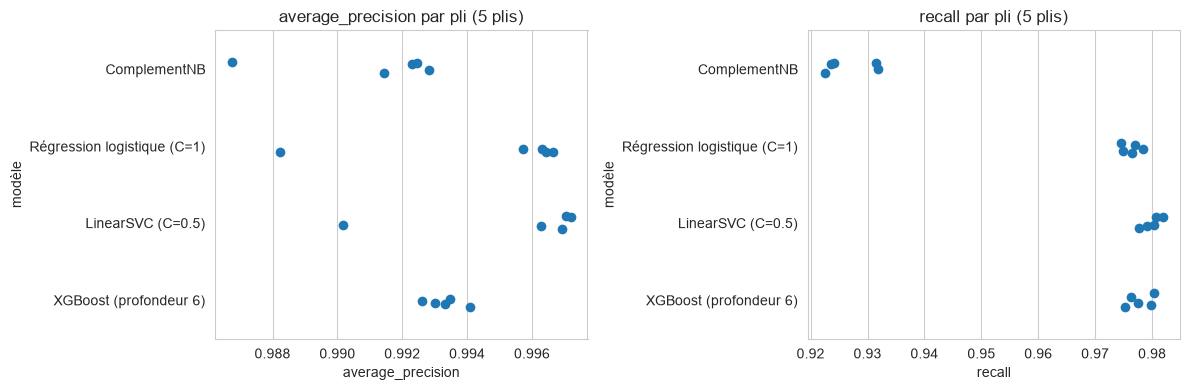

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["average_precision", "recall"]):
    rows = [(n, v) for n, sc in model_runs.items() if "Dummy" not in n for v in sc[metric]]
    plot_df = pd.DataFrame(rows, columns=["modèle", metric])
    sns.stripplot(data=plot_df, y="modèle", x=metric, ax=ax, size=7)
    ax.set_title(f"{metric} par pli (5 plis)")
plt.tight_layout()
plt.show()

## 4. Régler les hyperparamètres des meilleures familles

On explore peu de configurations, volontairement : sur un corpus aussi séparable, l'écart se joue sur le réglage de la régularisation (LR) et la profondeur (XGBoost), pas sur une recherche exhaustive. Les configurations sont jugées sur les mêmes plis.

Précaution : choisir la meilleure configuration sur les plis qui servent à l'évaluer rend le score de CV légèrement optimiste. L'estimation non biaisée est celle du **test** (section 7).

Temps indicatif : les fits XGBoost sont les plus longs (plusieurs minutes par configuration sur ~65 000 emails × 5 000 colonnes). Passer `QUICK = True` pour un essai rapide.

In [11]:
tuning_runs = {}

for C in [0.3, 3, 10, 30]:
    name = f"Régression logistique (C={C})"
    factories[name] = partial(make_logreg, N_COLS_USE, N_NUM_USE, C)
    run_cv(name, factories[name](), X_use, tuning_runs)

for depth in [4, 8]:
    name = f"XGBoost (profondeur {depth})"
    factories[name] = partial(make_xgb, depth)
    run_cv(name, factories[name](), X_use, tuning_runs)

all_runs = {**model_runs, **tuning_runs}


def best_of(prefix):
    cands = {n: sc for n, sc in all_runs.items() if n.startswith(prefix)}
    return max(cands, key=lambda n: cands[n]["average_precision"].mean())


best_lr_name = best_of("Régression logistique")
best_xgb_name = best_of("XGBoost")
print("\nMeilleure LR     :", best_lr_name)
print("Meilleur XGBoost :", best_xgb_name)

Régression logistique (C=0.3)                 AP=0.9934 ± 0.0037 |     2s
Régression logistique (C=3)                   AP=0.9954 ± 0.0033 |     3s
Régression logistique (C=10)                  AP=0.9959 ± 0.0021 |     4s
Régression logistique (C=30)                  AP=0.9957 ± 0.0021 |     2s
XGBoost (profondeur 4)                        AP=0.9902 ± 0.0006 |   234s
XGBoost (profondeur 8)                        AP=0.9947 ± 0.0006 |   677s

Meilleure LR     : Régression logistique (C=10)
Meilleur XGBoost : XGBoost (profondeur 8)


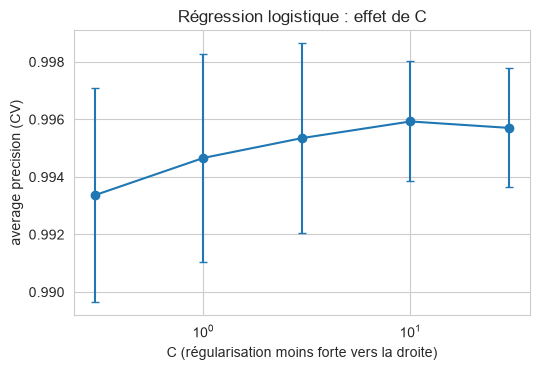

,average_precision,roc_auc,recall,precision,f1,fit (s/pli)
modèle,,,,,,
Régression logistique (C=10),0.9959 ± 0.0021,0.9966 ± 0.0007,0.9783 ± 0.0016,0.9742 ± 0.0014,0.9763 ± 0.0004,0.7
Régression logistique (C=30),0.9957 ± 0.0021,0.9964 ± 0.0007,0.9769 ± 0.0016,0.9736 ± 0.0010,0.9753 ± 0.0007,0.5
LinearSVC (C=0.5),0.9955 ± 0.0030,0.9967 ± 0.0007,0.9799 ± 0.0016,0.9738 ± 0.0016,0.9768 ± 0.0005,0.8
Régression logistique (C=3),0.9954 ± 0.0033,0.9966 ± 0.0007,0.9782 ± 0.0017,0.9742 ± 0.0015,0.9762 ± 0.0008,0.6
Régression logistique (C=1),0.9947 ± 0.0036,0.9961 ± 0.0007,0.9763 ± 0.0015,0.9712 ± 0.0017,0.9737 ± 0.0008,0.5
XGBoost (profondeur 8),0.9947 ± 0.0006,0.9950 ± 0.0004,0.9788 ± 0.0021,0.9544 ± 0.0022,0.9665 ± 0.0017,135.0
Régression logistique (C=0.3),0.9934 ± 0.0037,0.9949 ± 0.0008,0.9706 ± 0.0017,0.9678 ± 0.0027,0.9692 ± 0.0016,0.3
XGBoost (profondeur 6),0.9933 ± 0.0006,0.9937 ± 0.0004,0.9778 ± 0.0022,0.9445 ± 0.0020,0.9609 ± 0.0017,84.0
ComplementNB,0.9912 ± 0.0025,0.9920 ± 0.0012,0.9267 ± 0.0046,0.9679 ± 0.0021,0.9469 ± 0.0033,0.1


In [12]:
lr_rows = sorted(((float(n.split("C=")[1].rstrip(")")), sc["average_precision"]) for n, sc in all_runs.items()
                  if n.startswith("Régression logistique")), key=lambda t: t[0])
fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.errorbar([c for c, _ in lr_rows], [a.mean() for _, a in lr_rows],
            yerr=[a.std(ddof=1) for _, a in lr_rows], marker="o", capsize=3)
ax.set_xscale("log")
ax.set_xlabel("C (régularisation moins forte vers la droite)")
ax.set_ylabel("average precision (CV)")
ax.set_title("Régression logistique : effet de C")
plt.tight_layout()
plt.show()

summary_table(all_runs).sort_values("average_precision", ascending=False)

## 5. Tester un blend LR + XGBoost

Si les deux modèles se trompent sur des emails *différents*, leur moyenne peut faire mieux que chacun. Test honnête : on construit des prédictions **out-of-fold** (chaque email est prédit par un modèle qui ne l'a jamais vu, avec les mêmes plis), on moyenne les probabilités avec un poids `w` et on compare, pli par pli, au meilleur modèle seul.

D'abord, un diagnostic : les erreurs se recouvrent-elles ? Si les deux modèles se trompent presque toujours ensemble, le blend n'a rien à corriger.

In [13]:
oof = {}
for key, name in [("lr", best_lr_name), ("xgb", best_xgb_name)]:
    oof[key] = cross_val_predict(factories[name](), X_use, y, cv=splits, method="predict_proba")[:, 1]


def fold_ap(p):
    return np.array([average_precision_score(y[va], p[va]) for _, va in splits])


err_lr = (oof["lr"] >= 0.5) != y
err_xgb = (oof["xgb"] >= 0.5) != y
print(f"Erreurs LR seule      : {int((err_lr & ~err_xgb).sum())}")
print(f"Erreurs XGBoost seul  : {int((~err_lr & err_xgb).sum())}")
print(f"Erreurs communes      : {int((err_lr & err_xgb).sum())}")
print(f"Corrélation des probabilités OOF : {np.corrcoef(oof['lr'], oof['xgb'])[0, 1]:.3f}")

Erreurs LR seule      : 735
Erreurs XGBoost seul  : 1360
Erreurs communes      : 726
Corrélation des probabilités OOF : 0.965


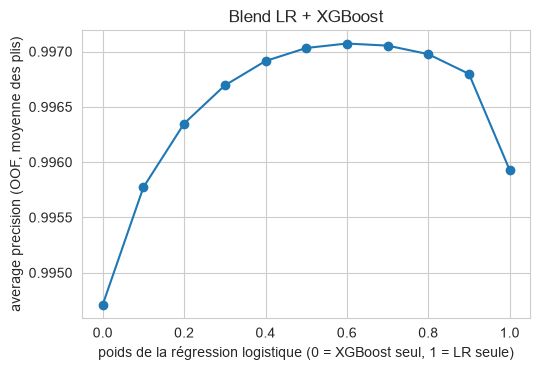

Meilleur poids LR : 0.6


In [14]:
weights_grid = np.round(np.arange(0, 1.01, 0.1), 1)   # poids de la LR
blend_curve = [(w, fold_ap(w * oof["lr"] + (1 - w) * oof["xgb"])) for w in weights_grid]
best_w = max(blend_curve, key=lambda t: t[1].mean())[0]
p_blend = best_w * oof["lr"] + (1 - best_w) * oof["xgb"]

fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.plot(weights_grid, [a.mean() for _, a in blend_curve], marker="o")
ax.set_xlabel("poids de la régression logistique (0 = XGBoost seul, 1 = LR seule)")
ax.set_ylabel("average precision (OOF, moyenne des plis)")
ax.set_title("Blend LR + XGBoost")
plt.tight_layout()
plt.show()
print("Meilleur poids LR :", best_w)

### Décision (règle séquentielle, du plus simple au plus complexe)

LR → XGBoost seulement s'il bat nettement la LR → blend seulement s'il bat nettement le choix courant.

In [15]:
oof_candidates = {"logreg": oof["lr"], "xgb": oof["xgb"], "blend": p_blend}
fold_scores = {k: fold_ap(p) for k, p in oof_candidates.items()}
for k, s in fold_scores.items():
    print(f"{k:<7} AP par pli : {np.round(s, 4)} | moyenne {s.mean():.4f}")

choice = "logreg"
for challenger in ["xgb", "blend"]:
    better, gain, se = is_better(fold_scores[challenger], fold_scores[choice])
    print(f"\n{challenger} vs {choice} : gain {gain:+.4f} (erreur-type {se:.4f}) -> "
          + ("RETENU, gain suffisant" if better else "rejeté, gain insuffisant"))
    if better:
        choice = challenger

print(f"\nMODÈLE RETENU : {choice}")
p_oof = oof_candidates[choice]
if choice == "logreg":
    final_spec = [(best_lr_name, 1.0)]
elif choice == "xgb":
    final_spec = [(best_xgb_name, 1.0)]
else:
    final_spec = [(best_lr_name, best_w), (best_xgb_name, round(1 - best_w, 1))]
print("Composition :", final_spec)

logreg  AP par pli : [0.9963 0.9972 0.9969 0.997  0.9922] | moyenne 0.9959
xgb     AP par pli : [0.9945 0.9947 0.9951 0.9954 0.9939] | moyenne 0.9947
blend   AP par pli : [0.997  0.9975 0.9975 0.9976 0.9958] | moyenne 0.9971

xgb vs logreg : gain -0.0012 (erreur-type 0.0007) -> rejeté, gain insuffisant

blend vs logreg : gain +0.0011 (erreur-type 0.0006) -> rejeté, gain insuffisant

MODÈLE RETENU : logreg
Composition : [('Régression logistique (C=10)', 1.0)]


## 6. Calibration, seuil de décision et zone d'incertitude

La cascade du projet (ML d'abord, LLM + RAG pour les cas douteux) a besoin de **probabilités fiables**, pas seulement d'un bon classement. On regarde donc la calibration des candidats, puis on fixe, **sur les prédictions out-of-fold du modèle retenu** (jamais sur le test) :

- un **seuil opérationnel** : le seuil le plus élevé qui garantit un recall phishing ≥ `TARGET_RECALL` (donc le moins de faux positifs possible sous cette contrainte) ;
- une **zone d'incertitude** `[t_bas, t_haut]` : sous `t_bas`, quasiment aucun phishing (recall ≥ `BAND_RECALL`) ; au-dessus de `t_haut`, quasiment aucun légitime (précision ≥ `BAND_PRECISION`). Seuls les emails dans la zone seraient envoyés au LLM.

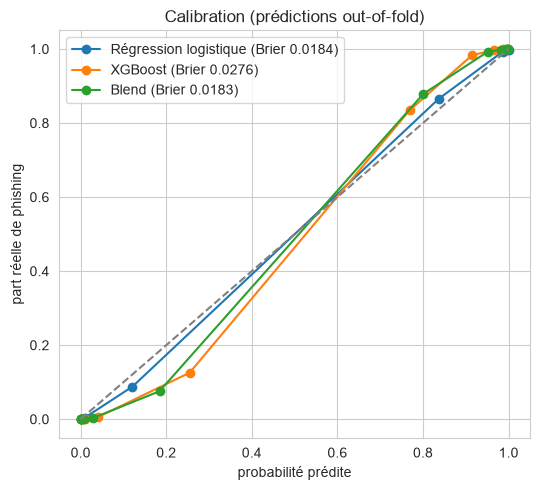

In [16]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for label, p in [("Régression logistique", oof["lr"]), ("XGBoost", oof["xgb"]), ("Blend", p_blend)]:
    frac_pos, mean_pred = calibration_curve(y, p, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=f"{label} (Brier {brier_score_loss(y, p):.4f})")
ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set_xlabel("probabilité prédite")
ax.set_ylabel("part réelle de phishing")
ax.set_title("Calibration (prédictions out-of-fold)")
ax.legend()
plt.tight_layout()
plt.show()

In [17]:
TARGET_RECALL = 0.98
BAND_RECALL = 0.995
BAND_PRECISION = 0.995

prec, rec, thr = precision_recall_curve(y, p_oof)
prec, rec = prec[:-1], rec[:-1]

ok_op = rec >= TARGET_RECALL
threshold_op = float(thr[ok_op].max()) if ok_op.any() else 0.5

ok_low = rec >= BAND_RECALL
t_low = float(thr[ok_low].max()) if ok_low.any() else float(thr.min())
ok_high = prec >= BAND_PRECISION
t_high = float(thr[ok_high].min()) if ok_high.any() else 1.0
if t_low > t_high:   # zone vide ou contradictoire : on se replie sur le seuil opérationnel
    t_low = t_high = threshold_op


def metrics_at(y_true, p, t):
    pred = (p >= t).astype(int)
    return {"seuil": round(t, 4), "recall": recall_score(y_true, pred), "précision": precision_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred), "faux négatifs": int(((pred == 0) & (y_true == 1)).sum()),
            "faux positifs": int(((pred == 1) & (y_true == 0)).sum())}


oof_table = pd.DataFrame({"seuil 0,5": metrics_at(y, p_oof, 0.5), "seuil opérationnel": metrics_at(y, p_oof, threshold_op)}).T
print(oof_table.round(4).to_string())

in_band = (p_oof >= t_low) & (p_oof <= t_high)
pred_oof = (p_oof >= threshold_op).astype(int)
print(f"\nZone d'incertitude [{t_low:.3f}, {t_high:.3f}] : {in_band.mean():.1%} des emails envoyés au LLM")
print(f"Taux d'erreur hors zone : {(pred_oof[~in_band] != y[~in_band]).mean():.4f} | dans la zone : {(pred_oof[in_band] != y[in_band]).mean():.4f}")

                     seuil  recall  précision      f1  faux négatifs  faux positifs
seuil 0,5           0.5000  0.9783     0.9742  0.9763          665.0          796.0
seuil opérationnel  0.4648  0.9800     0.9718  0.9759          613.0          873.0

Zone d'incertitude [0.117, 0.929] : 10.2% des emails envoyés au LLM
Taux d'erreur hors zone : 0.0051 | dans la zone : 0.1903


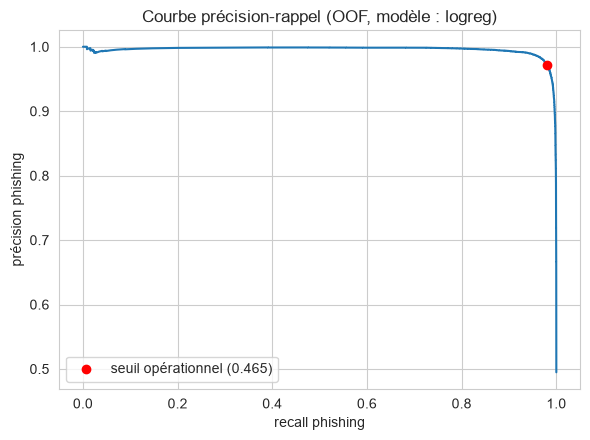

In [18]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(rec, prec)
ax.scatter([recall_score(y, pred_oof)], [precision_score(y, pred_oof)], color="red", zorder=3, label=f"seuil opérationnel ({threshold_op:.3f})")
ax.set_xlabel("recall phishing")
ax.set_ylabel("précision phishing")
ax.set_title(f"Courbe précision-rappel (OOF, modèle : {choice})")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Évaluation finale sur le test (une seule fois)

Le modèle (ou le blend), les features, le seuil et la zone d'incertitude sont **figés** par les sections précédentes. On réentraîne sur **tout** le train, on charge le test (construit au notebook 02 avec les mêmes transformations que le train) et on mesure. Aucune décision ne sera modifiée après ce point.

In [19]:
final_models = [factories[name]().fit(X_use, y) for name, _ in final_spec]
final_weights = [w for _, w in final_spec]


def predict_proba_bundle(models, weights, X):
    return sum(w * m.predict_proba(X)[:, 1] for m, w in zip(models, weights))


X_test_all = sp.load_npz(DATA / "emails_X_test.npz").tocsr()
y_test = np.load(DATA / "emails_y_test.npy")
assert X_test_all.shape[1] == X_all.shape[1]
X_test_use = X_test_all[:, keep_cols]

p_test = predict_proba_bundle(final_models, final_weights, X_test_use)
print("X_test:", X_test_use.shape, "| phishing :", round(y_test.mean(), 3))

test_table = pd.DataFrame({"seuil 0,5": metrics_at(y_test, p_test, 0.5),
                           "seuil opérationnel": metrics_at(y_test, p_test, threshold_op)}).T
print(test_table.round(4).to_string())
print(f"\nROC-AUC test : {roc_auc_score(y_test, p_test):.4f} | average precision test : {average_precision_score(y_test, p_test):.4f}")
print()
print(classification_report(y_test, (p_test >= threshold_op).astype(int), target_names=["légitime", "phishing"]))

X_test: (15511, 4914) | phishing : 0.495
                     seuil  recall  précision      f1  faux négatifs  faux positifs
seuil 0,5           0.5000  0.9803     0.9735  0.9769          151.0          205.0
seuil opérationnel  0.4648  0.9827     0.9709  0.9768          133.0          226.0

ROC-AUC test : 0.9973 | average precision test : 0.9973

              precision    recall  f1-score   support

    légitime       0.98      0.97      0.98      7836
    phishing       0.97      0.98      0.98      7675

    accuracy                           0.98     15511
   macro avg       0.98      0.98      0.98     15511
weighted avg       0.98      0.98      0.98     15511



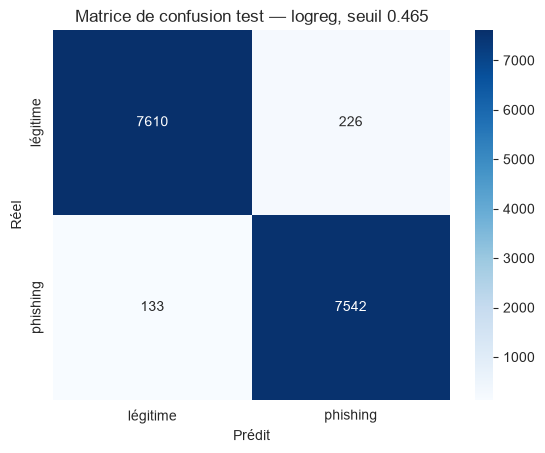

In [20]:
cm = confusion_matrix(y_test, (p_test >= threshold_op).astype(int))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["légitime", "phishing"], yticklabels=["légitime", "phishing"])
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.title(f"Matrice de confusion test — {choice}, seuil {threshold_op:.3f}")
plt.show()

### Intervalles de confiance (bootstrap) et cohérence CV ↔ test

Un chiffre de test seul ne dit rien de sa précision. On rééchantillonne le test 500 fois pour obtenir un intervalle à 95 %, et on compare au score out-of-fold au même seuil : un écart important entre les deux signalerait un problème (fuite en CV, ou distribution du test différente).

In [21]:
rng = np.random.RandomState(RANDOM_STATE)
pred_test = (p_test >= threshold_op).astype(int)
boot = {"recall": [], "précision": [], "average_precision": []}
for _ in range(500):
    i = rng.randint(0, len(y_test), len(y_test))
    boot["recall"].append(recall_score(y_test[i], pred_test[i]))
    boot["précision"].append(precision_score(y_test[i], pred_test[i], zero_division=0))
    boot["average_precision"].append(average_precision_score(y_test[i], p_test[i]))

rows = []
oof_op = metrics_at(y, p_oof, threshold_op)
test_op = metrics_at(y_test, p_test, threshold_op)
for m, ref in [("recall", oof_op["recall"]), ("précision", oof_op["précision"]), ("average_precision", average_precision_score(y, p_oof))]:
    lo, hi = np.percentile(boot[m], [2.5, 97.5])
    test_val = test_op[m] if m in test_op else average_precision_score(y_test, p_test)
    rows.append({"métrique": m, "CV (OOF)": round(ref, 4), "test": round(test_val, 4), "IC95% test": f"[{lo:.4f} ; {hi:.4f}]"})
pd.DataFrame(rows).set_index("métrique")

,CV (OOF),test,IC95% test
métrique,,,
recall,0.9800,0.9827,[0.9797 ; 0.9852]
précision,0.9718,0.9709,[0.9672 ; 0.9743]
average_precision,0.9956,0.9973,[0.9967 ; 0.9978]


## 8. Ce que le modèle regarde, sauvegarde et rechargement

**Interprétation.** Vérifier que les mots les plus influents ont un sens métier (et pas seulement un nom de source). Pour la régression logistique : coefficients ; pour XGBoost : importance. Calculé sur le modèle entraîné sur le train, sans information du test.

In [22]:
def top_features(model, k=15):
    clf = model[-1] if isinstance(model, Pipeline) else model
    if hasattr(clf, "coef_"):
        coef = clf.coef_.ravel()
        order = np.argsort(coef)
        pos = [(str(n), round(float(c), 2)) for n, c in zip(names_use[order[-k:]][::-1], coef[order[-k:]][::-1])]
        neg = [(str(n), round(float(c), 2)) for n, c in zip(names_use[order[:k]], coef[order[:k]])]
        return "coef", pos, neg
    imp = clf.feature_importances_
    order = np.argsort(imp)[::-1][:k]
    return "importance", [(str(n), round(float(v), 4)) for n, v in zip(names_use[order], imp[order])], None


for (name, _), model in zip(final_spec, final_models):
    kind, pos, neg = top_features(model)
    print(f"=== {name} ({kind}) ===")
    print("Poussent vers PHISHING / plus importants :", pos)
    if neg is not None:
        print("Poussent vers LÉGITIME :", neg)
    print()

=== Régression logistique (C=10) (coef) ===
Poussent vers PHISHING / plus importants : [('replica', 9.7), ('monkeyorg', 8.51), ('remove', 8.27), ('http', 7.92), ('investment', 7.61), ('ine', 7.28), ('paliourg', 7.08), ('meds', 7.07), ('kindly', 6.83), ('viagra', 6.81), ('love', 6.81), ('statements', 6.66), ('mobile email', 6.55), ('phone mobile', 6.25), ('quality', 6.22)]
Poussent vers LÉGITIME : [('wrote', -21.2), ('thanks', -12.68), ('forwarded', -11.72), ('url', -11.31), ('university', -10.97), ('ierant', -10.91), ('employees', -10.44), ('corp', -10.28), ('fork', -9.6), ('date', -9.55), ('cheers', -8.58), ('daren', -8.57), ('february', -8.56), ('mailing list', -8.48), ('houston', -8.39)]



**Sauvegarde.** Un seul fichier `email_model.joblib` (nom stable pour l'API) contenant : les modèles, leurs poids, le seuil opérationnel, la zone d'incertitude et `keep_cols` (colonnes à garder dans la matrice complète produite par le vectorizer + les features numériques, voir la fin du notebook 02). Une fiche JSON résume les décisions et les chiffres pour le README et la soutenance.

Format volontairement simple (dictionnaire, pas de classe maison) : le fichier se recharge sans dépendre du code du notebook. Probabilité finale = somme pondérée des `predict_proba` des modèles.

In [23]:
bundle = {
    "kind": choice,
    "models": final_models,
    "weights": final_weights,
    "threshold": threshold_op,
    "uncertainty_band": [t_low, t_high],
    "keep_cols": keep_cols,
    "feature_names": list(names_use),
    "numeric_features": NUM_NAMES if USE_NUMERIC else [],
    "sklearn_version": sklearn.__version__,
}
joblib.dump(bundle, MODELS / "email_model.joblib")

card = {
    "date": str(date.today()),
    "modèle_retenu": choice,
    "composition": [{"modèle": n, "poids": w} for n, w in final_spec],
    "features": {"numériques_utilisées": USE_NUMERIC, "marqueurs_de_source_retirés": found if DROP_MARKERS else [],
                 "n_colonnes": int(N_COLS_USE)},
    "validation": {"type": "StratifiedGroupKFold" if groups is not None else "StratifiedKFold",
                   "n_plis": N_SPLITS, "métrique_de_sélection": "average_precision", "min_gain": MIN_GAIN},
    "cv_average_precision": {k: round(float(v.mean()), 4) for k, v in fold_scores.items()},
    "seuil_opérationnel": round(threshold_op, 4),
    "zone_incertitude": [round(t_low, 4), round(t_high, 4)],
    "test": {k: (v if isinstance(v, (int, str)) else round(float(v), 4)) for k, v in test_op.items()},
    "test_roc_auc": round(float(roc_auc_score(y_test, p_test)), 4),
    "test_average_precision": round(float(average_precision_score(y_test, p_test)), 4),
    "mode_rapide": QUICK,
}
with open(MODELS / "email_model_card.json", "w", encoding="utf-8") as f:
    json.dump(card, f, ensure_ascii=False, indent=2)
print(json.dumps(card, ensure_ascii=False, indent=2))

{
  "date": "2026-10-09",
  "modèle_retenu": "logreg",
  "composition": [
    {
      "modèle": "Régression logistique (C=10)",
      "poids": 1.0
    }
  ],
  "features": {
    "numériques_utilisées": false,
    "marqueurs_de_source_retirés": [
      "enron",
      "enron com",
      "enron corp",
      "enron enron",
      "enron enronxgate",
      "enron north",
      "enron subject",
      "enronxgate",
      "corp enron",
      "ect enron",
      "ect",
      "ect ect",
      "ect subject",
      "hou",
      "hou ect",
      "vince",
      "kaminski",
      "kaminski enron",
      "kaminski hou",
      "vince kaminski",
      "america corp",
      "louise",
      "kitchen louise",
      "hpl",
      "ena",
      "scheduling",
      "scheduling iso",
      "california scheduling",
      "westdesk",
      "portland westdesk",
      "westdesk california",
      "hourahead",
      "hourahead hour",
      "date hourahead",
      "hour start",
      "hour ancillary",
      "ancillary s

**Contrôle de rechargement.** On recharge le fichier et on vérifie qu'il redonne exactement les mêmes probabilités : sinon, mieux vaut le savoir avant de brancher l'API.

In [24]:
reloaded = joblib.load(MODELS / "email_model.joblib")
p_reloaded = predict_proba_bundle(reloaded["models"], reloaded["weights"], X_test_all[:, reloaded["keep_cols"]])
assert np.allclose(p_reloaded, p_test), "Le modèle rechargé ne redonne pas les mêmes probabilités"
print("Rechargement OK : mêmes probabilités que le modèle en mémoire.")

Rechargement OK : mêmes probabilités que le modèle en mémoire.


## Conclusion 

Modèle retenu : régression logistique (C = 10) sur TF-IDF seul, sans features numériques et sans marqueurs de source. Seuil opérationnel: 0,4648. Zone d’incertitude : [0,117 ; 0,929].

Pourquoi ce modèle? La sélection s’est faite par validation croisée groupée à 5 plis sur le train, avec des plis identiques pour tous les modèles. La règle de décision était écrite avant les résultats : on prend le modèle le plus simple, et on ne passe à plus complexe que si le gain d’average precision dépasse 0,001 et 2 erreurs-types.

Régression logistique : AP de 0,9959 en validation croisée.
XGBoost (profondeur 8) : AP de 0,9947, donc légèrement en dessous, avec une précision plus faible (0,954 contre 0,974). Il est aussi environ 200 fois plus lent à entraîner (135 s contre 0,7 s par pli).
Blend LR + XGBoost : gain de +0,0011 pour une erreur-type de 0,0006, rejeté de justesse (2 erreurs-types = 0,0012). Ce gain est trop petit pour justifier un second modèle, et les deux modèles se trompent sur les mêmes emails (corrélation des probabilités de 0,965).
ComplementNB et LinearSVC : ComplementNB est nettement derrière (AP de 0,991, recall de 0,927). LinearSVC est à égalité statistique (0,9955), mais sans probabilités natives, ce qui le rend moins adapté à la cascade ML → LLM.